<a href="https://colab.research.google.com/github/Euripedes357/GMSF/blob/main/BRAIN_TUMOR_MRI_Quando_uma_Rede_Convolucional_Aprende_a_Olhar_o_Cerebro.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Passo 1 — Conectar o Google Drive e localizar o arquivo

O conjunto de dados foi baixado do Kaggle como `archive.zip` e guardado no Google Drive do autor, na pasta `BRAIN TUMOR MRI - by Euripedes Gomes`. O comando `drive.mount` conecta o Drive ao Colab (pede autorização da conta Google na primeira execução), e o Drive passa a ser acessível como uma pasta em `/content/drive/MyDrive/`.

As duas linhas de `print` conferem que o arquivo foi encontrado e que o tamanho bate com o esperado (cerca de 164,7 MB). Essa conferência evita trabalhar, sem perceber, com um arquivo diferente do que foi auditado.

In [22]:
# Passo 1 — Conectar o Google Drive ao Colab e localizar o archive.zip
import os
from google.colab import drive

drive.mount('/content/drive')

ZIP_DRIVE = '/content/drive/MyDrive/BRAIN TUMOR MRI - by Euripedes Gomes/archive.zip'

print('Arquivo existe?', os.path.exists(ZIP_DRIVE))
print('Tamanho (MB)  :', round(os.path.getsize(ZIP_DRIVE) / 1e6, 1))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Arquivo existe? True
Tamanho (MB)  : 164.7


## Passo 2 — Descompactar as imagens e preparar a pasta do relatório

O Drive montado é lento para ler milhares de arquivos pequenos. Por isso o zip é copiado para o disco local da máquina do Colab (`/content/`) e descompactado em `/content/data`. Esse disco é apagado ao fim da sessão, mas o zip original permanece no Drive, bastando repetir os Passos 1 e 2 para reconstruir tudo.

A célula também cria a pasta `relatorio/` dentro da pasta do projeto no Drive. Todas as figuras (`fig01_...png`) e tabelas (`tab01_...csv`) geradas ao longo do notebook serão gravadas nela, prontas para o relatório final.

Como alguns zips do Kaggle trazem uma pasta-raiz extra, as pastas `Training` e `Testing` são localizadas com `glob` em qualquer nível. A lista de classes vem dos nomes das subpastas — no dataset, o nome da pasta é o rótulo.

In [23]:
# Passo 2 — Descompactar o archive.zip no disco local do Colab e criar a pasta do relatório
import zipfile, shutil, glob

PASTA_PROJETO = '/content/drive/MyDrive/BRAIN TUMOR MRI - by Euripedes Gomes'
RELATORIO_DIR = PASTA_PROJETO + '/relatorio'   # figuras e tabelas para o Word
ZIP_LOCAL     = '/content/archive.zip'
DATA_DIR      = '/content/data'

os.makedirs(RELATORIO_DIR, exist_ok=True)
shutil.copy(ZIP_DRIVE, ZIP_LOCAL)             # copia o zip do Drive para o disco do Colab
zipfile.ZipFile(ZIP_LOCAL).extractall(DATA_DIR)

TRAIN_DIR = glob.glob(DATA_DIR + '/**/Training', recursive=True)[0]
TEST_DIR  = glob.glob(DATA_DIR + '/**/Testing',  recursive=True)[0]
CLASSES   = sorted(os.listdir(TRAIN_DIR))

print('Pasta do relatório:', RELATORIO_DIR)
print('Training          :', TRAIN_DIR)
print('Testing           :', TEST_DIR)
print('Classes           :', CLASSES)

Pasta do relatório: /content/drive/MyDrive/BRAIN TUMOR MRI - by Euripedes Gomes/relatorio
Training          : /content/data/Training
Testing           : /content/data/Testing
Classes           : ['glioma', 'meningioma', 'notumor', 'pituitary']


**Observação:** a cópia e a descompactação levaram cerca de 8 segundos. O zip não traz pasta-raiz extra: `Training` e `Testing` ficaram diretamente em `/content/data/`. As quatro classes foram reconhecidas a partir dos nomes das subpastas, em ordem alfabética — `glioma`, `meningioma`, `notumor`, `pituitary` — e essa será a ordem dos rótulos (0, 1, 2, 3) em todo o notebook. A pasta `relatorio/` foi criada no Drive, ainda vazia.

## Passo 3 — Ambiente de execução, versões e sementes

O critério 1 do professor pede linguagem, versões, bibliotecas e ambiente. Esta célula importa as bibliotecas que serão usadas em todo o notebook (NumPy, Pandas, Matplotlib, Pillow, scikit-learn e TensorFlow/Keras) e imprime a versão de cada uma, além de verificar se há GPU disponível.

A célula também fixa a semente (`SEED = 42`) no Python, no NumPy e no TensorFlow. A semente controla tudo o que envolve sorteio — embaralhamento das imagens, divisão treino/validação, inicialização dos pesos da rede — para que uma nova execução reproduza os mesmos resultados. A reprodutibilidade completa em GPU não é garantida (algumas operações da GPU são não determinísticas), e isso será declarado como limitação no relatório.

**Observação:** a cópia e a descompactação levaram cerca de 8 segundos. O zip não traz pasta-raiz extra: `Training` e `Testing` ficaram diretamente em `/content/data/`. As quatro classes foram reconhecidas a partir dos nomes das subpastas, em ordem alfabética — `glioma`, `meningioma`, `notumor`, `pituitary` — e essa será a ordem dos rótulos (0, 1, 2, 3) em todo o notebook. A pasta `relatorio/` foi criada no Drive, ainda vazia.

In [24]:
# Passo 3 — Ambiente de execução, versões das bibliotecas e sementes
import sys, random, platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import PIL
import sklearn
import tensorflow as tf
from tensorflow import keras

# Sementes fixas para reprodutibilidade
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print('Python       :', platform.python_version())
print('TensorFlow   :', tf.__version__)
print('Keras        :', keras.__version__)
print('NumPy        :', np.__version__)
print('Pandas       :', pd.__version__)
print('Matplotlib   :', matplotlib.__version__)
print('Pillow       :', PIL.__version__)
print('scikit-learn :', sklearn.__version__)
print('GPU          :', tf.config.list_physical_devices('GPU'))
print('Semente      :', SEED)

Python       : 3.13.16
TensorFlow   : 2.21.0
Keras        : 3.13.2
NumPy        : 2.4.6
Pandas       : 2.2.3
Matplotlib   : 3.10.0
Pillow       : 11.3.0
scikit-learn : 1.6.1
GPU          : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Semente      : 42


**Observação:** o ambiente é o Google Colab com GPU NVIDIA T4, Python 3.13.16, TensorFlow 2.21.0, Keras 3.13.2, NumPy 2.4.6, Pandas 2.2.3, Matplotlib 3.10.0, Pillow 11.3.0 e scikit-learn 1.6.1, com semente fixa 42. Estas versões são as que constarão na seção de ambiente do relatório e no README do repositório.

### Bibliotecas utilizadas

Cada biblioteca resolve um problema específico da cadeia que vai do arquivo de imagem ao resultado da rede.

**Python 3.13** — linguagem em que todo o notebook é escrito; padrão de fato em ciência de dados e aprendizado profundo.

**Pillow 11.3** (Clark et al., 2015) — *abrir as imagens.* Um JPEG é um formato comprimido; o Pillow o descompacta em pixels, lê dimensões e modo de cor, converte para tons de cinza e redimensiona. É a porta entre o arquivo no disco e a matemática.

**NumPy 2.4** (Harris et al., 2020) — *calcular.* Uma imagem 128×128 é uma matriz de 16.384 números; o NumPy opera sobre matrizes inteiras de uma só vez, o que torna viável o processamento de milhares de imagens. Todas as estatísticas da análise exploratória são calculadas com ele.

**Pandas 2.2** (McKinney, 2010) — *organizar em tabelas.* Equivale a uma planilha dentro do Python: contagens por classe, tabelas de qualidade dos dados e a comparação entre experimentos, exportadas em CSV para o relatório.

**Matplotlib 3.10** (Hunter, 2007) — *desenhar.* Transforma números em figuras com título, eixos e legenda: distribuição das classes, exemplos de imagens, curvas de treino e validação e matriz de confusão, gravadas em PNG.

**TensorFlow 2.21** (Abadi et al., 2016) — *treinar.* É o motor do aprendizado profundo: calcula automaticamente os gradientes de milhões de parâmetros (retropropagação) e executa as operações na GPU.

**Keras 3.13** (Chollet et al., 2015) — *descrever a rede.* Interface de alto nível sobre o TensorFlow: a CNN é definida camada a camada, com função de perda, otimizador e métricas, sem programar a matemática do treinamento.

**scikit-learn 1.6** (Pedregosa et al., 2011) — *dividir e avaliar.* Faz a divisão estratificada entre treino e validação e calcula as métricas com a definição correta: acurácia, precisão, revocação, F1 e matriz de confusão. Não treina a rede; atua antes e depois dela.

**Google Colab** — ambiente de execução em nuvem que hospeda o notebook e fornece a GPU NVIDIA T4.

As referências completas de cada biblioteca, no formato NBR 6023, constarão na lista final do relatório, na ordem da primeira citação.

## Definição do problema

**Tarefa.** Classificação de imagens de ressonância magnética cerebral em quatro categorias: *glioma*, *meningioma*, *pituitary* e *notumor*. Da mesma saída deriva-se a leitura binária entre presença e ausência de tumor, sem treinar outra rede. Ficam fora do escopo a segmentação, a localização do tumor, o grau, o prognóstico e qualquer uso clínico.

**Entrada e resposta.** A entrada é uma imagem de RM, padronizada para 128×128 pixels em tons de cinza. A resposta é a classe da imagem, codificada como um vetor de quatro probabilidades (uma por classe), cuja maior probabilidade define a predição.

**Por que uma CNN.** Uma imagem é uma matriz de pixels cuja informação está na relação espacial entre vizinhos. Achatá-la em vetor para uma rede densa descartaria essa estrutura e elevaria o número de parâmetros; filtros convolucionais com pesos compartilhados detectam padrões locais em qualquer posição, e o pooling resume a informação espacial.

**Pergunta de pesquisa.** Em que medida uma CNN simples, avaliada sem vazamento entre treinamento, validação e teste, classifica corretamente as quatro categorias, e como as decisões de treinamento e regularização contribuem para sua generalização?

**Objetivo geral.** Desenvolver e avaliar uma CNN para a classificação de imagens de RM cerebral em quatro categorias, com avaliação final em conjunto de teste preservado.

**Objetivos específicos.** (i) Caracterizar o conjunto e auditar sua qualidade, incluindo duplicidades e possível vazamento entre os subconjuntos; (ii) construir a rede e treiná-la com validação independente; (iii) comparar configurações de taxa de aprendizado, Early Stopping, Dropout e aumento de dados; (iv) avaliar o desempenho com acurácia, precisão, revocação, F1 e matriz de confusão, incluindo a leitura binária.

## Passo 4 — Distribuição das imagens por subconjunto e classe

O critério 1 pede o número de observações e a distribuição das classes. Esta célula conta as imagens de cada classe em `Training` e `Testing`, monta a tabela de contagem e desenha o primeiro gráfico do trabalho.

A contagem serve a dois propósitos. Primeiro, conferir se o arquivo analisado reproduz o levantamento do documento de definição (1.400 imagens por classe no Training e 400 no Testing, 7.200 no total). Segundo, verificar o balanceamento: classes equilibradas dispensam técnicas de compensação (pesos de classe ou reamostragem) e permitem usar a acurácia como métrica principal sem distorção.

A tabela é gravada em `relatorio/tab01_distribuicao_classes.csv` e o gráfico em `relatorio/fig01_distribuicao_classes.png`, os primeiros itens do relatório final.

Subconjunto  Training  Testing  Total
Classe                               
glioma           1400      400   1800
meningioma       1400      400   1800
notumor          1400      400   1800
pituitary        1400      400   1800
Total            5600     1600   7200


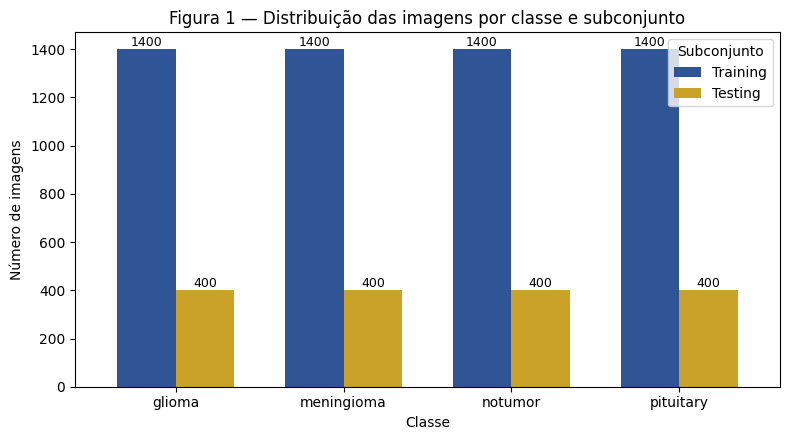

In [25]:
# Passo 4 — Contagem de imagens por subconjunto e classe, tabela e gráfico
SUBSETS = {'Training': TRAIN_DIR, 'Testing': TEST_DIR}

linhas = []
for nome, pasta in SUBSETS.items():
    for cls in CLASSES:
        n = len(os.listdir(os.path.join(pasta, cls)))
        linhas.append({'Subconjunto': nome, 'Classe': cls, 'Imagens': n})

contagem = (pd.DataFrame(linhas)
              .pivot(index='Classe', columns='Subconjunto', values='Imagens')
              [['Training', 'Testing']])
contagem['Total'] = contagem.sum(axis=1)
contagem.loc['Total'] = contagem.sum()

print(contagem)
contagem.to_csv(os.path.join(RELATORIO_DIR, 'tab01_distribuicao_classes.csv'))

# Gráfico de barras agrupadas (sem a linha Total)
dados = contagem.drop(index='Total')[['Training', 'Testing']]
fig, ax = plt.subplots(figsize=(8, 4.5))
dados.plot(kind='bar', ax=ax, color=['#2F5597', '#C9A227'], width=0.7)
ax.set_title('Figura 1 — Distribuição das imagens por classe e subconjunto')
ax.set_xlabel('Classe')
ax.set_ylabel('Número de imagens')
ax.legend(title='Subconjunto')
ax.tick_params(axis='x', rotation=0)
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width()/2, p.get_height()),
                ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(RELATORIO_DIR, 'fig01_distribuicao_classes.png'), dpi=200)
plt.show()

**Observação:** a contagem reproduz integralmente o levantamento do documento de definição: 1.400 imagens por classe no Training (5.600) e 400 por classe no Testing (1.600), totalizando 7.200. As quatro classes são perfeitamente balanceadas nos dois subconjuntos, o que dispensa pesos de classe ou reamostragem e autoriza o uso da acurácia como métrica principal, complementada por precisão, revocação e F1 por classe. A contagem difere da descrição pública do dataset (7.023 imagens), e por isso todas as estatísticas deste trabalho se referem ao arquivo efetivamente analisado. Tabela e figura gravadas em `relatorio/tab01_distribuicao_classes.csv` e `relatorio/fig01_distribuicao_classes.png`.

# Fase 2 — Preparação e análise exploratória

Esta fase responde ao critério 2 do professor: conhecer os tipos de dado, procurar duplicidades e valores extremos, justificar as transformações e dividir treino, validação e teste sem vazamento. Antes de qualquer tratamento, a base é auditada como foi recebida.

## Passo 5 — Dimensões, modo de cor e integridade dos arquivos

Uma rede convolucional exige que todas as imagens tenham o mesmo tamanho e o mesmo número de canais, e o conjunto não garante isso. Esta célula abre o cabeçalho de cada uma das 7.200 imagens com o Pillow, sem carregar todos os pixels, e registra a largura, a altura e o modo de cor (`L` é um canal em tons de cinza, `RGB` são três canais, `RGBA` e `P` são variantes). Qualquer arquivo que não abrir é contabilizado como corrompido.

O objetivo é reproduzir no Colab o levantamento preliminar do documento de definição (Tabela 4) e verificar se tamanho e cor se associam à classe. Se isso acontecer, a rede pode aprender atributos do arquivo, como o tamanho ou a codificação de cor, em vez da anatomia do cérebro, e a acurácia ficaria inflada sem o modelo saber ler uma ressonância.

O resultado é gravado em `relatorio/tab02_dimensoes_modos.csv`, e os números do notebook prevalecem sobre os do levantamento feito fora dele.

In [26]:
# Passo 5 — Dimensões, modo de cor e integridade de todas as imagens
from PIL import Image

registros = []
corrompidos = []

for sub, pasta in SUBSETS.items():
    for cls in CLASSES:
        pasta_cls = os.path.join(pasta, cls)
        for arq in sorted(os.listdir(pasta_cls)):
            caminho = os.path.join(pasta_cls, arq)
            try:
                with Image.open(caminho) as img:      # lê só o cabeçalho, não os pixels
                    largura, altura = img.size
                    modo = img.mode
                registros.append({'subconjunto': sub, 'classe': cls, 'arquivo': arq,
                                  'largura': largura, 'altura': altura, 'modo': modo})
            except Exception as erro:
                corrompidos.append((caminho, str(erro)))

df = pd.DataFrame(registros)
df['dimensao'] = df['largura'].astype(str) + '×' + df['altura'].astype(str)

# Tabela-resumo por subconjunto e classe (equivale à Tabela 4 do documento de definição)
linhas = []
for sub in SUBSETS:
    for cls in CLASSES:
        g = df[(df['subconjunto'] == sub) & (df['classe'] == cls)]
        dims = g['dimensao'].value_counts()
        modos = g['modo'].value_counts()
        linhas.append({
            'Subconjunto': sub,
            'Classe': cls,
            'Dimensões distintas': g['dimensao'].nunique(),
            'Mais frequente (n)': f'{dims.index[0]} ({dims.iloc[0]})',
            'Modo de cor (n)': '; '.join(f'{m} {n}' for m, n in modos.items()),
        })
tabela = pd.DataFrame(linhas)

print(f'Imagens lidas      : {len(df)}')
print(f'Arquivos corrompidos: {len(corrompidos)}')
print()
print(tabela.to_string(index=False))

tabela.to_csv(os.path.join(RELATORIO_DIR, 'tab02_dimensoes_modos.csv'), index=False)

Imagens lidas      : 7200
Arquivos corrompidos: 0

Subconjunto     Classe  Dimensões distintas Mais frequente (n)             Modo de cor (n)
   Training     glioma                    1     512×512 (1400)             L 1173; RGB 227
   Training meningioma                  116     512×512 (1267)              RGB 845; L 555
   Training    notumor                  250      225×225 (240) RGB 1373; L 23; RGBA 3; P 1
   Training  pituitary                   27     512×512 (1328)              RGB 793; L 607
    Testing     glioma                   62      512×512 (324)              L 226; RGB 174
    Testing meningioma                   99      512×512 (283)              RGB 246; L 154
    Testing    notumor                   55       225×225 (77)                RGB 394; L 6
    Testing  pituitary                    2      512×512 (392)               L 323; RGB 77


**Observação:** as 7.200 imagens foram lidas sem nenhum arquivo corrompido, e os números reproduzem integralmente o levantamento preliminar do documento de definição (Tabela 4). O tamanho das imagens não é único: o glioma do Training tem uma única dimensão (512×512), o meningioma tem 116, o pituitary tem 27 e o notumor tem 250, com apenas 240 imagens no tamanho mais frequente (225×225). O modo de cor também se associa à classe: no Training, 98% das imagens notumor estão em RGB (1.373 de 1.400), contra 16% no glioma (227), 60% no meningioma (845) e 57% no pituitary (793); há ainda quatro imagens notumor em modos raros (3 em RGBA e 1 em P). Training e Testing também diferem entre si, como no pituitary (57% em RGB no Training e 19% no Testing) e no glioma (16% contra 44%). Como tamanho e cor revelam parte da classe, a rede poderia aprender atributos do arquivo em vez da anatomia; a padronização para um único tamanho e para tons de cinza, prevista no Passo 10, reduz essas pistas, mas não necessariamente todas, e isso será declarado como limitação.

### Figura 2 — Modo de cor por classe e subconjunto

A tabela acima é precisa, mas difícil de comparar de relance. O gráfico abaixo mostra, para cada combinação de subconjunto e classe, a proporção de imagens em cada modo de cor (tons de cinza `L`, `RGB`, `RGBA` e `P`). Se o modo de cor fosse independente da classe, as oito barras teriam a mesma composição; diferenças marcantes entre elas indicam que a cor funciona como pista para a classe.

O gráfico é gravado em `relatorio/fig02_modo_cor_por_classe.png`.

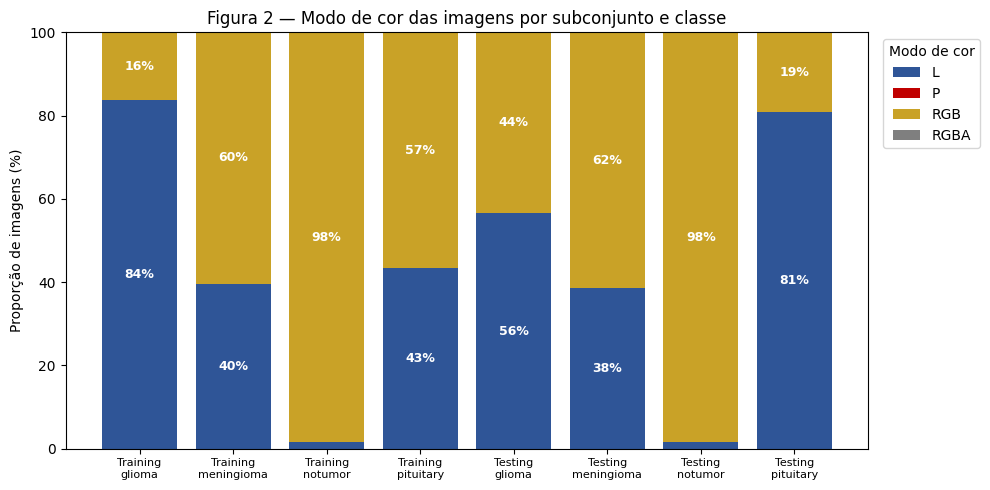

In [27]:
# Figura 2 — Proporção de imagens por modo de cor, por subconjunto e classe
prop = (pd.crosstab([df['subconjunto'], df['classe']], df['modo'], normalize='index') * 100)
prop = prop.reindex([(s, c) for s in SUBSETS for c in CLASSES])   # ordem fixa
prop.index = [f'{s}\n{c}' for s, c in prop.index]

cores = {'L': '#2F5597', 'RGB': '#C9A227', 'RGBA': '#7F7F7F', 'P': '#C00000'}
fig, ax = plt.subplots(figsize=(10, 5))
base = np.zeros(len(prop))
for modo in prop.columns:
    ax.bar(prop.index, prop[modo], bottom=base, label=modo, color=cores.get(modo, '#999999'))
    for i, v in enumerate(prop[modo]):
        if v >= 6:
            ax.text(i, base[i] + v / 2, f'{v:.0f}%', ha='center', va='center',
                    color='white', fontsize=9, fontweight='bold')
    base += prop[modo].values

ax.set_title('Figura 2 — Modo de cor das imagens por subconjunto e classe')
ax.set_ylabel('Proporção de imagens (%)')
ax.set_ylim(0, 100)
ax.legend(title='Modo de cor', loc='upper left', bbox_to_anchor=(1.01, 1))
plt.xticks(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(RELATORIO_DIR, 'fig02_modo_cor_por_classe.png'), dpi=200, bbox_inches='tight')
plt.show()

**Observação:** o modo de cor separa as classes com clareza. O `notumor` é quase inteiramente RGB nos dois subconjuntos (98% no Training e 98% no Testing), ao passo que as classes com tumor misturam tons de cinza e RGB em proporções variadas: glioma com 16% de RGB no Training e 44% no Testing, meningioma com 60% e 62%, e pituitary com 57% e 19%. Se o modo de cor fosse independente da classe, as oito barras teriam composição semelhante, e isso não ocorre. Além disso, a mesma classe muda de composição entre Training e Testing (glioma e pituitary de forma marcante), o que sugere que os dois subconjuntos foram montados a partir de misturas diferentes de fontes de imagem. Em consequência, tamanho e cor são atalhos disponíveis para a rede, e o Testing pode não ter a mesma distribuição do Training. A conversão de todas as imagens para um único tamanho e para tons de cinza (Passo 10) remove essas duas pistas, mas não outras associadas à origem das imagens, como recorte e contraste, e essa limitação será declarada no relatório. Figura gravada em `relatorio/fig02_modo_cor_por_classe.png`.

## Passo 6 — Duplicatas exatas (hash MD5)

Imagens idênticas dentro do mesmo conjunto fazem a rede ver o mesmo exemplo várias vezes, o que dá mais peso a ele no treino. Pior: se uma cópia cair no treino e outra na validação, a validação deixa de ser independente e a acurácia fica inflada.

Esta célula calcula, para cada arquivo, o hash MD5, uma "impressão digital" de 32 caracteres calculada sobre todos os bytes do arquivo: dois arquivos com bytes idênticos geram o mesmo hash. Agrupando as imagens pelo hash, encontramos os grupos de cópias exatas e verificamos em que subconjunto e em que classe cada grupo está, em particular se existe alguma cópia entre Training e Testing.

O MD5 só detecta cópias byte a byte. Imagens que mostram o mesmo corte com recorte, compressão ou contraste diferentes têm hashes distintos, e por isso a busca por quase-duplicatas é feita separadamente, no Passo 7.

O resultado é gravado em `relatorio/tab03_duplicatas_md5.csv`. O levantamento preliminar do documento de definição encontrou 153 grupos, com 340 imagens envolvidas, todos dentro do mesmo subconjunto e da mesma classe; o notebook deve reproduzir esses números.

In [28]:
# Passo 6 — Duplicatas exatas por hash MD5
import hashlib

def md5_arquivo(caminho):
    h = hashlib.md5()
    with open(caminho, 'rb') as f:
        for bloco in iter(lambda: f.read(1024 * 1024), b''):   # lê em blocos de 1 MB
            h.update(bloco)
    return h.hexdigest()

# Caminho completo de cada imagem e o hash do arquivo
df['caminho'] = [os.path.join(SUBSETS[s], c, a)
                 for s, c, a in zip(df['subconjunto'], df['classe'], df['arquivo'])]
df['md5'] = df['caminho'].apply(md5_arquivo)

# Grupos de hash que aparecem mais de uma vez
contagem_hash = df['md5'].value_counts()
hashes_dup = contagem_hash[contagem_hash > 1].index
dup = df[df['md5'].isin(hashes_dup)].copy()

n_grupos = len(hashes_dup)
n_imagens = len(dup)
print(f'Grupos de imagens idênticas        : {n_grupos}')
print(f'Imagens envolvidas nos grupos      : {n_imagens}')
print(f'Cópias excedentes (além da 1ª)     : {n_imagens - n_grupos}')

# Algum grupo atravessa subconjuntos ou classes?
escopo = dup.groupby('md5').agg(subconjuntos=('subconjunto', 'nunique'),
                                classes=('classe', 'nunique'))
print(f'Grupos entre Training e Testing    : {(escopo["subconjuntos"] > 1).sum()}')
print(f'Grupos com classes diferentes      : {(escopo["classes"] > 1).sum()}')

# Resumo por subconjunto e classe
resumo = (dup.groupby(['subconjunto', 'classe'])
             .agg(Grupos=('md5', 'nunique'), Imagens=('md5', 'size'))
             .reset_index())
resumo['Cópias excedentes'] = resumo['Imagens'] - resumo['Grupos']
print()
print(resumo.to_string(index=False))

resumo.to_csv(os.path.join(RELATORIO_DIR, 'tab03_duplicatas_md5.csv'), index=False)
dup[['md5', 'subconjunto', 'classe', 'arquivo']].sort_values(['md5', 'subconjunto']).to_csv(
    os.path.join(RELATORIO_DIR, 'lista_duplicatas_md5.csv'), index=False)

Grupos de imagens idênticas        : 153
Imagens envolvidas nos grupos      : 340
Cópias excedentes (além da 1ª)     : 187
Grupos entre Training e Testing    : 0
Grupos com classes diferentes      : 0

subconjunto     classe  Grupos  Imagens  Cópias excedentes
    Testing     glioma      13       27                 14
    Testing meningioma       2        4                  2
   Training meningioma      13       27                 14
   Training    notumor      97      216                119
   Training  pituitary      28       66                 38


### Figura 3 — Cópias exatas por subconjunto e classe

O gráfico abaixo mostra, em cada combinação de subconjunto e classe, o número de cópias excedentes (imagens idênticas a outra do mesmo grupo, além da primeira) e o percentual que elas representam do total de imagens daquela combinação. O percentual permite comparar grupos de tamanhos diferentes.

O gráfico é gravado em `relatorio/fig03_duplicatas_md5.png`.

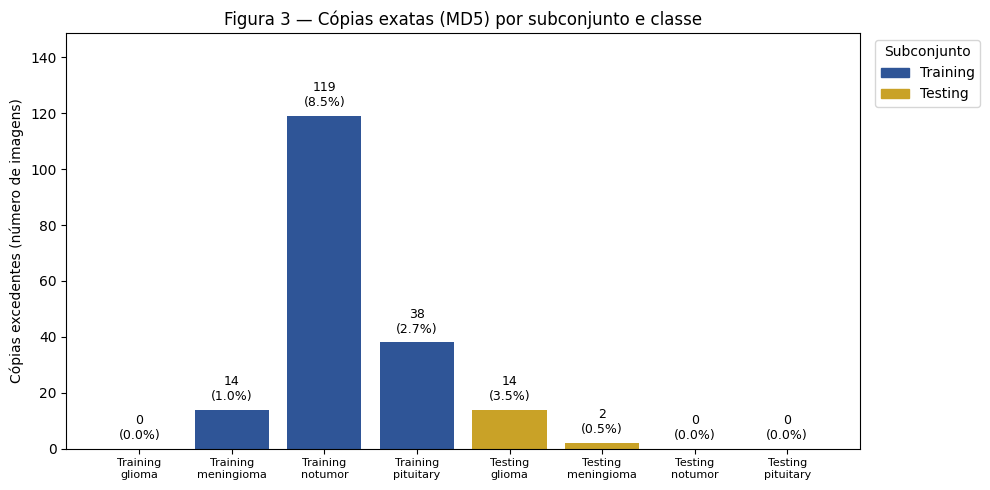

In [29]:
# Figura 3 — Cópias exatas (MD5) por subconjunto e classe
from matplotlib.patches import Patch

chaves = [(s, c) for s in SUBSETS for c in CLASSES]
total = df.groupby(['subconjunto', 'classe']).size().reindex(chaves)
exc = resumo.set_index(['subconjunto', 'classe'])['Cópias excedentes'].reindex(chaves, fill_value=0)
pct = exc / total * 100

cores = ['#2F5597' if s == 'Training' else '#C9A227' for s, c in chaves]
rotulos = [f'{s}\n{c}' for s, c in chaves]

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(rotulos, exc.values, color=cores)
for i, (n, p) in enumerate(zip(exc.values, pct.values)):
    ax.text(i, n + exc.max() * 0.02, f'{n}\n({p:.1f}%)', ha='center', va='bottom', fontsize=9)

ax.set_title('Figura 3 — Cópias exatas (MD5) por subconjunto e classe')
ax.set_ylabel('Cópias excedentes (número de imagens)')
ax.set_ylim(0, exc.max() * 1.25)
ax.legend(handles=[Patch(color='#2F5597', label='Training'), Patch(color='#C9A227', label='Testing')],
          title='Subconjunto', loc='upper left', bbox_to_anchor=(1.01, 1))
plt.xticks(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(RELATORIO_DIR, 'fig03_duplicatas_md5.png'), dpi=200, bbox_inches='tight')
plt.show()

**Observação:** a busca por hash MD5 reproduz o levantamento preliminar do documento de definição: 153 grupos de imagens idênticas, envolvendo 340 imagens, ou seja, 187 cópias excedentes. Nenhum grupo atravessa Training e Testing, e nenhum reúne imagens de classes diferentes; portanto não há vazamento por cópia exata entre os subconjuntos, e os rótulos são coerentes entre as cópias. As duplicatas se concentram no Training, sobretudo no notumor (119 cópias excedentes, 8,5% da classe), seguido do pituitary (38, 2,7%) e do meningioma (14, 1,0%); o glioma do Training não tem nenhuma. No Testing há 14 cópias excedentes no glioma (3,5%) e 2 no meningioma (0,5%). Dentro do Training, as cópias dariam peso extra a certos exemplos e, numa divisão aleatória entre treino e validação, deixariam uma cópia de cada lado, o que inflaria a validação; por isso a divisão será feita por grupos de imagens semelhantes (Passo 9), e as cópias exatas ficarão sempre do mesmo lado. O MD5 não detecta o mesmo corte com recorte ou contraste diferentes, o que será examinado no Passo 7. Tabela e figura gravadas em `relatorio/tab03_duplicatas_md5.csv` e `relatorio/fig03_duplicatas_md5.png`; a lista dos arquivos duplicados está em `relatorio/lista_duplicatas_md5.csv`.

## Passo 7 — Quase-duplicatas entre Training e Testing

O MD5 só encontra cópias idênticas byte a byte. O mesmo corte de ressonância salvo com outro recorte, outra compressão ou outro contraste tem um hash completamente diferente, mas continua sendo, para a rede, a mesma imagem. Se uma imagem do Testing tem uma "gêmea" no Training, o modelo já a viu no treino, e a acurácia medida no Testing fica superestimada.

Para medir isso sem depender do arquivo, cada imagem é convertida para tons de cinza, reduzida a 48×48 pixels e normalizada (média zero e norma unitária). A similaridade entre duas imagens passa a ser a correlação de Pearson entre esses vetores: 1,0 significa imagens idênticas no padrão de intensidades, e valores próximos de 1 indicam o mesmo corte com pequenas diferenças. Para cada imagem do Testing, procuramos a imagem mais parecida no Training e registramos a correlação máxima e se as duas pertencem à mesma classe.

Os resultados são resumidos por limiar de correlação (0,999, 0,99, 0,98 e 0,95) e gravados em `relatorio/tab04_quase_duplicatas.csv`. Como não há identificação de paciente, a correlação é um substituto imperfeito: cortes diferentes do mesmo paciente podem não ser detectados, e imagens distintas muito parecidas podem ser tratadas como cópias. O levantamento preliminar do documento de definição encontrou 420 imagens do Testing (26,3%) com correlação acima de 0,999, 451 (28,2%) acima de 0,99 e 492 (30,8%) acima de 0,98; o notebook deve reproduzir esses números.

In [30]:
# Passo 7 — Quase-duplicatas: correlação de Pearson entre imagens 48x48 em tons de cinza
def vetor_48(caminho):
    with Image.open(caminho) as img:
        a = np.asarray(img.convert('L').resize((48, 48), Image.BILINEAR), dtype=np.float32).ravel()
    a = a - a.mean()                      # média zero
    n = np.linalg.norm(a)
    return a / n if n > 0 else a          # norma unitária: o produto escalar vira a correlação

tr = df[df['subconjunto'] == 'Training'].reset_index(drop=True)
te = df[df['subconjunto'] == 'Testing'].reset_index(drop=True)

X_tr = np.stack([vetor_48(c) for c in tr['caminho']])
X_te = np.stack([vetor_48(c) for c in te['caminho']])
print('Matrizes de vetores:', X_tr.shape, X_te.shape)

# Testing x Training: para cada imagem do Testing, a mais parecida do Training
C = X_te @ X_tr.T
melhor = C.argmax(axis=1)
te['corr_max'] = C.max(axis=1)
te['vizinho_caminho'] = tr['caminho'].values[melhor]
te['classe_vizinho'] = tr['classe'].values[melhor]
te['mesma_classe'] = te['classe'] == te['classe_vizinho']

# Visto do lado do Training: quantas imagens têm gêmea no Testing
tr['corr_max_testing'] = C.max(axis=0)

# Resumo por limiar de correlação
linhas = []
for t in [0.999, 0.99, 0.98, 0.95]:
    m = te['corr_max'] > t
    linhas.append({'Correlação maior que': t,
                   'Imagens do Testing com vizinho no Training': int(m.sum()),
                   '% das 1.600 imagens': round(100 * m.mean(), 1),
                   'Vizinho da mesma classe': int((m & te['mesma_classe']).sum())})
tab04 = pd.DataFrame(linhas)
print()
print(tab04.to_string(index=False))

# Dentro do Training: imagens com outra imagem muito parecida
C2 = X_tr @ X_tr.T
np.fill_diagonal(C2, -1)
tr['corr_max_training'] = C2.max(axis=1)
del C2
n_in = int((tr['corr_max_training'] > 0.99).sum())
n_out = int((tr['corr_max_testing'] > 0.99).sum())
print()
print(f'Training com outra imagem do Training (corr > 0,99): {n_in} de {len(tr)} ({100*n_in/len(tr):.1f}%)')
print(f'Training com imagem do Testing (corr > 0,99)       : {n_out} de {len(tr)} ({100*n_out/len(tr):.1f}%)')

tab04.to_csv(os.path.join(RELATORIO_DIR, 'tab04_quase_duplicatas.csv'), index=False)

Matrizes de vetores: (5600, 2304) (1600, 2304)

 Correlação maior que  Imagens do Testing com vizinho no Training  % das 1.600 imagens  Vizinho da mesma classe
                0.999                                         420                 26.2                      418
                0.990                                         451                 28.2                      449
                0.980                                         492                 30.8                      490
                0.950                                         802                 50.1                      798

Training com outra imagem do Training (corr > 0,99): 1170 de 5600 (20.9%)
Training com imagem do Testing (corr > 0,99)       : 733 de 5600 (13.1%)


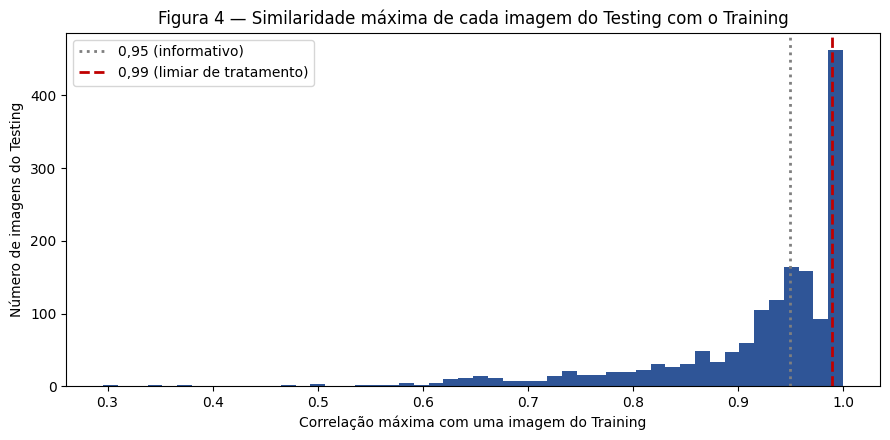

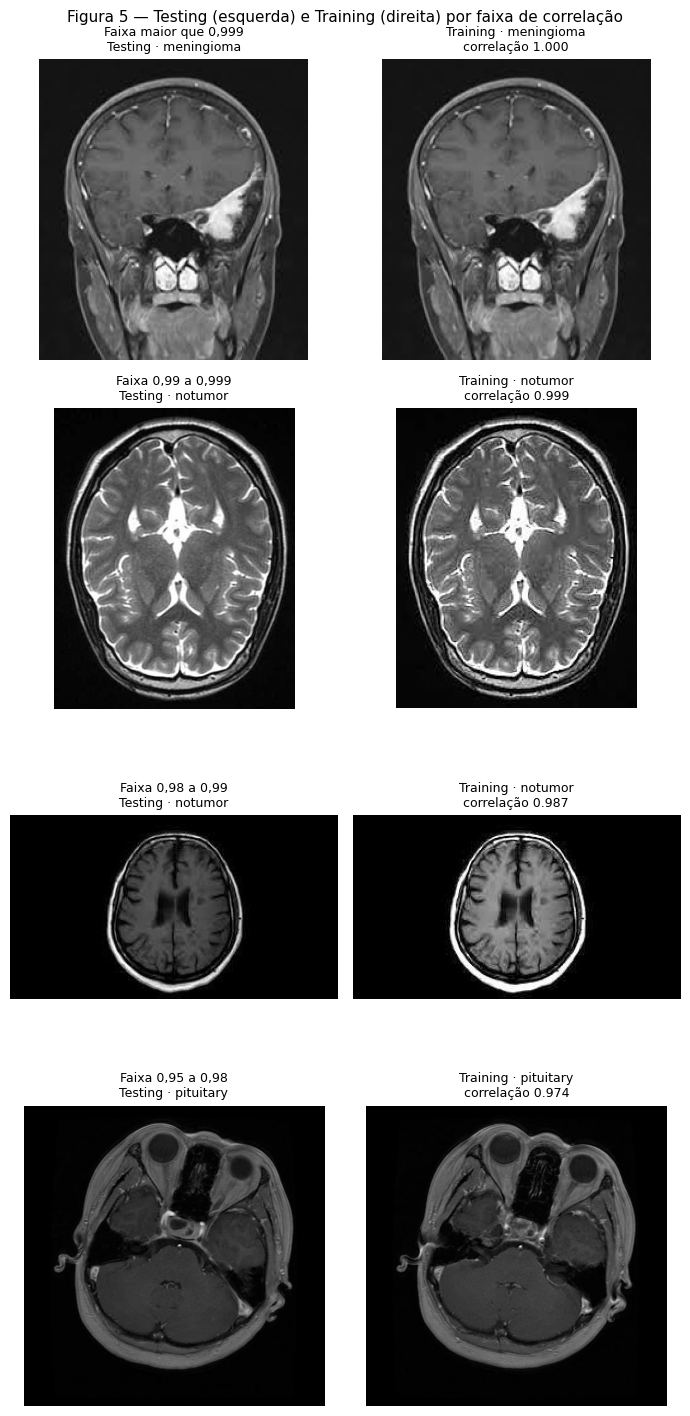

In [31]:
# Figuras 4 e 5 — Quase-duplicatas entre Testing e Training
rng = np.random.default_rng(SEED)

# Figura 4 — distribuição da correlação máxima (Testing x Training)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(te['corr_max'], bins=50, color='#2F5597')
ax.axvline(0.95, color='#7F7F7F', linestyle=':', linewidth=2, label='0,95 (informativo)')
ax.axvline(0.99, color='#C00000', linestyle='--', linewidth=2, label='0,99 (limiar de tratamento)')
ax.set_title('Figura 4 — Similaridade máxima de cada imagem do Testing com o Training')
ax.set_xlabel('Correlação máxima com uma imagem do Training')
ax.set_ylabel('Número de imagens do Testing')
ax.legend(loc='upper left')
plt.tight_layout()
plt.savefig(os.path.join(RELATORIO_DIR, 'fig04_distribuicao_correlacao.png'), dpi=200)
plt.show()

# Figura 5 — um par sorteado em cada faixa de correlação
faixas = [('maior que 0,999', 0.999, 1.1),
          ('0,99 a 0,999', 0.99, 0.999),
          ('0,98 a 0,99', 0.98, 0.99),
          ('0,95 a 0,98', 0.95, 0.98)]
fig, eixos = plt.subplots(len(faixas), 2, figsize=(7, 3.6 * len(faixas)))
for linha, (nome, lo, hi) in enumerate(faixas):
    cand = te[(te['corr_max'] > lo) & (te['corr_max'] <= hi)]
    if len(cand) == 0:
        eixos[linha, 0].axis('off'); eixos[linha, 1].axis('off')
        continue
    r = cand.iloc[int(rng.integers(len(cand)))]
    eixos[linha, 0].imshow(Image.open(r['caminho']).convert('L'), cmap='gray')
    eixos[linha, 0].set_title(f"Faixa {nome}\nTesting · {r['classe']}", fontsize=9)
    eixos[linha, 1].imshow(Image.open(r['vizinho_caminho']).convert('L'), cmap='gray')
    eixos[linha, 1].set_title(f"Training · {r['classe_vizinho']}\ncorrelação {r['corr_max']:.3f}", fontsize=9)
    eixos[linha, 0].axis('off'); eixos[linha, 1].axis('off')
fig.suptitle('Figura 5 — Testing (esquerda) e Training (direita) por faixa de correlação', fontsize=11)
plt.tight_layout()
plt.savefig(os.path.join(RELATORIO_DIR, 'fig05_pares_quase_duplicatas.png'), dpi=200, bbox_inches='tight')
plt.show()

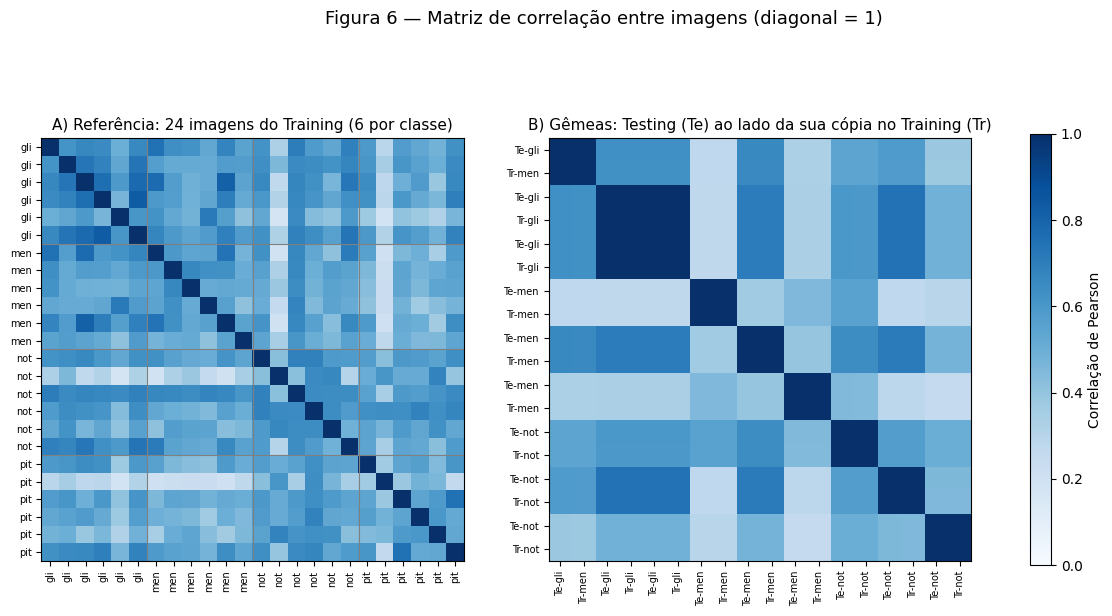

Painel A — correlação média fora da diagonal: 0.537 | máxima: 0.830
Painel B — correlação dos pares Testing×Training: mín 1.000 | média 1.000


In [32]:
# Figura 6 — Matriz de correlação: amostra de referência (A) e pares Testing×Training (B)
rng = np.random.default_rng(SEED)

# Painel A: 6 imagens do Training por classe, ordenadas por classe
idx_a = []
for c in CLASSES:
    pos = np.where(tr['classe'].values == c)[0]
    idx_a += list(rng.choice(pos, 6, replace=False))
V_a = X_tr[idx_a]
M_a = V_a @ V_a.T                      # vetores normalizados: produto escalar = Pearson
rot_a = [tr['classe'].iloc[i][:3] for i in idx_a]

# Painel B: 3 imagens do Testing por classe com corr_max > 0,99, cada uma seguida da sua gêmea do Training
pares = []
for c in CLASSES:
    cand = te.index[(te['classe'] == c) & (te['corr_max'] > 0.99)].values
    pares += list(rng.choice(cand, min(3, len(cand)), replace=False))
V_b, rot_b = [], []
for i in pares:
    V_b += [X_te[i], X_tr[melhor[i]]]
    rot_b += ['Te-' + te['classe'].iloc[i][:3], 'Tr-' + tr['classe'].iloc[melhor[i]][:3]]
V_b = np.stack(V_b)
M_b = V_b @ V_b.T

fig, eixos = plt.subplots(1, 2, figsize=(15, 7))
paineis = [(M_a, rot_a, 'A) Referência: 24 imagens do Training (6 por classe)'),
           (M_b, rot_b, 'B) Gêmeas: Testing (Te) ao lado da sua cópia no Training (Tr)')]
for ax, (M, rot, titulo) in zip(eixos, paineis):
    im = ax.imshow(M, cmap='Blues', vmin=0, vmax=1)
    ax.set_xticks(range(len(rot)))
    ax.set_yticks(range(len(rot)))
    ax.set_xticklabels(rot, rotation=90, fontsize=7)
    ax.set_yticklabels(rot, fontsize=7)
    ax.set_title(titulo, fontsize=11)
# separadores de classe no painel A (a cada 6 imagens)
for k in range(6, 24, 6):
    eixos[0].axhline(k - 0.5, color='gray', lw=0.8)
    eixos[0].axvline(k - 0.5, color='gray', lw=0.8)
fig.colorbar(im, ax=eixos, shrink=0.8, label='Correlação de Pearson')
fig.suptitle('Figura 6 — Matriz de correlação entre imagens (diagonal = 1)', fontsize=13)
fig.savefig(f'{RELATORIO_DIR}/fig06_matriz_correlacao.png', dpi=200, bbox_inches='tight')
plt.show()

# Números para a Observação
fora_a = M_a[~np.eye(len(M_a), dtype=bool)]
print(f'Painel A — correlação média fora da diagonal: {fora_a.mean():.3f} | máxima: {fora_a.max():.3f}')
corr_pares = [M_b[2*k, 2*k + 1] for k in range(len(pares))]
print(f'Painel B — correlação dos pares Testing×Training: mín {min(corr_pares):.3f} | média {np.mean(corr_pares):.3f}')

Entre as 451 imagens do Testing com gêmea acima de 0,99 no Training, 449 (99,6%) têm o mesmo rótulo da gêmea e 2 têm rótulo divergente (glioma no Testing e meningioma no Training), indício de ruído de rotulagem no próprio conjunto; as gêmeas concentram-se em notumor (340) e meningioma (104), com 7 em glioma e nenhuma em pituitary.

In [33]:
# Conferência: as gêmeas do Testing (corr > 0,99) têm o mesmo rótulo no Training?
gemeas = te[te['corr_max'] > 0.99]
print(gemeas['mesma_classe'].value_counts())
print()
print(pd.crosstab(gemeas['classe'], gemeas['classe_vizinho'],
                  rownames=['classe no Testing'], colnames=['classe da gêmea no Training']))


mesma_classe
True     449
False      2
Name: count, dtype: int64

classe da gêmea no Training  glioma  meningioma  notumor
classe no Testing                                       
glioma                            5           2        0
meningioma                        0         104        0
notumor                           0           0      340


**Observação:** a medição por correlação reproduz o levantamento preliminar do documento de definição. Das 1.600 imagens do Testing, 420 (26,3%) têm no Training uma imagem com correlação superior a 0,999, 451 (28,2%) superior a 0,99, 492 (30,8%) superior a 0,98 e 802 (50,1%) superior a 0,95. Mais de um quarto do Testing, portanto, não é inédito para o modelo, o que tende a superestimar a acurácia medida nele; a Figura 4 mostra essa concentração de imagens nas correlações mais altas, à direita do limiar de 0,99. No sentido inverso, 733 das 5.600 imagens do Training (13,1%) têm uma imagem muito parecida (correlação acima de 0,99) no Testing, número maior que 451 porque uma mesma imagem do Testing pode ter várias parecidas no Training. Dentro do próprio Training, 1.170 imagens (20,9%) têm outra imagem com correlação acima de 0,99, de modo que uma divisão aleatória entre treino e validação também deixaria cópias dos dois lados. Na Figura 5, o par sorteado na faixa de 0,98 a 0,99 (notumor, correlação 0,987) mostra o mesmo corte com enquadramento ligeiramente diferente, e não uma cópia idêntica. O limiar de 0,95 inclui cortes apenas semelhantes e, por isso, não é tratado como duplicidade. Como não há identificação de paciente, a correlação é um substituto imperfeito: pode deixar passar cortes diferentes do mesmo paciente e pode tratar imagens distintas muito parecidas como cópias. O tratamento proposto será aplicado no Passo 8, removendo do Training as imagens com correlação superior a 0,99 com alguma imagem do Testing, e no Passo 9, com a divisão entre treino e validação por grupos de imagens semelhantes. Tabela e figuras gravadas em `relatorio/tab04_quase_duplicatas.csv`, `relatorio/fig04_distribuicao_correlacao.png` e `relatorio/fig05_pares_quase_duplicatas.png`.

## Passo 8 — Tratamento da sobreposição: remoção, do Training, das imagens com gêmea no Testing

O Passo 7 mostrou que parte do Testing já aparece no Training, o que faria a acurácia final parecer melhor do que a capacidade real do modelo de reconhecer imagens inéditas. Para corrigir isso, este passo remove do Training toda imagem cuja correlação com alguma imagem do Testing seja superior a 0,99. A escolha foi retirar as cópias do Training, e não do Testing, por dois motivos: o Testing publicado permanece intacto, com 1.600 imagens, o que mantém os resultados comparáveis a outros trabalhos com o mesmo dataset; e as imagens removidas são cópias, de modo que o Training perde pouca informação nova. O custo é um Training menor.

O código separa as imagens a manter e as removidas, monta uma tabela por classe com as contagens antes e depois da limpeza, salva a tabela e a lista das imagens removidas em `relatorio/`, e faz uma verificação final: recalcula a maior correlação entre o Training limpo e o Testing, que deve ficar abaixo do limiar. As variáveis `tr_limpo` e `X_tr_limpo` guardam o Training limpo para os próximos passos.

In [34]:
# Passo 8 — Remoção, do Training, das imagens com gêmea no Testing (correlação > 0,99)
LIMIAR = 0.99
manter = (tr['corr_max_testing'] <= LIMIAR).values
tr_limpo = tr[manter].reset_index(drop=True)
X_tr_limpo = X_tr[manter]
removidas = tr[~manter]

# Tabela por classe: antes, removidas, depois
antes = tr['classe'].value_counts().reindex(CLASSES)
rem = removidas['classe'].value_counts().reindex(CLASSES).fillna(0).astype(int)
depois = tr_limpo['classe'].value_counts().reindex(CLASSES)
tab05 = pd.DataFrame({'Training original': antes,
                      'Removidas': rem,
                      'Training após limpeza': depois})
tab05['% removido'] = (100 * tab05['Removidas'] / tab05['Training original']).round(1)
tab05.loc['Total'] = [antes.sum(), rem.sum(), depois.sum(),
                      round(100 * rem.sum() / antes.sum(), 1)]
display(tab05)

# Verificação: nenhuma imagem do Training limpo pode ter correlação > limiar com o Testing
maior = (X_te @ X_tr_limpo.T).max()
print(f'\nMaior correlação Testing x Training limpo: {maior:.4f} (limiar {LIMIAR})')
print(f'Testing intacto: {len(te)} imagens')

# Salvar tabela e lista das imagens removidas
tab05.to_csv(f'{RELATORIO_DIR}/tab05_remocao_training.csv')
removidas[['classe', 'arquivo', 'caminho', 'corr_max_testing']].to_csv(
    f'{RELATORIO_DIR}/lista_removidas_training.csv', index=False)

,Training original,Removidas,Training após limpeza,% removido
classe,,,,
glioma,1400.0,4.0,1396.0,0.3
meningioma,1400.0,106.0,1294.0,7.6
notumor,1400.0,623.0,777.0,44.5
pituitary,1400.0,0.0,1400.0,0.0
Total,5600.0,733.0,4867.0,13.1



Maior correlação Testing x Training limpo: 0.9899 (limiar 0.99)
Testing intacto: 1600 imagens


**Figura 7 — Imagens mantidas e removidas do Training, por classe.** Cada barra representa as 1.400 imagens originais de uma classe no Training; a parte azul-escura é o que permanece após a limpeza e a parte azul-clara, no topo, é o que foi removido por ter uma gêmea (correlação superior a 0,99) no Testing. O texto acima de cada barra indica o número e a porcentagem removidos.

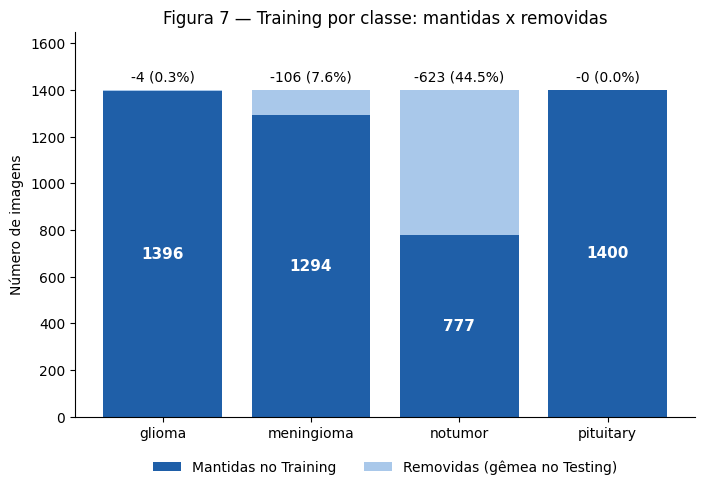

In [35]:
# Figura 7 — Training por classe: mantidas x removidas
mantidas = tab05.loc[CLASSES, 'Training após limpeza'].astype(int).values
removid = tab05.loc[CLASSES, 'Removidas'].astype(int).values
pct = tab05.loc[CLASSES, '% removido'].values
x = np.arange(len(CLASSES))

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(x, mantidas, color='#1f5fa8', label='Mantidas no Training')
ax.bar(x, removid, bottom=mantidas, color='#a9c8ea', label='Removidas (gêmea no Testing)')
for i in range(len(CLASSES)):
    ax.text(x[i], mantidas[i] / 2, f'{mantidas[i]}', ha='center', va='center',
            color='white', fontsize=11, fontweight='bold')
    ax.text(x[i], mantidas[i] + removid[i] + 25, f'-{removid[i]} ({pct[i]:.1f}%)',
            ha='center', va='bottom', fontsize=10)
ax.set_xticks(x)
ax.set_xticklabels(CLASSES)
ax.set_ylabel('Número de imagens')
ax.set_ylim(0, 1650)
ax.set_title('Figura 7 — Training por classe: mantidas x removidas', fontsize=12)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=2, frameon=False)
ax.spines[['top', 'right']].set_visible(False)
fig.savefig(f'{RELATORIO_DIR}/fig07_remocao_training.png', dpi=200, bbox_inches='tight')
plt.show()

## Passo 9 — Divisão treino/validação (80/20) por grupos de imagens semelhantes

O conjunto de validação serve para acompanhar o aprendizado durante o treino e escolher o número de épocas, por isso precisa conter imagens que a rede não viu. Se a divisão fosse sorteada imagem a imagem, cópias e quase-cópias do próprio Training (1.170 imagens com gêmea interna, Passo 7) ficariam dos dois lados, e a acurácia de validação sairia inflada, escondendo o momento em que a rede passa a decorar. Para evitar isso, as imagens do Training limpo são agrupadas por semelhança: duas imagens com correlação superior a 0,98 pertencem ao mesmo grupo, e os grupos são formados pelos componentes conexos desse critério (se A é parecida com B e B com C, as três ficam juntas). A divisão 80/20 é então feita por grupos, de modo que um grupo inteiro vai para o treino ou para a validação, mantendo aproximadamente a proporção de cada classe, com semente fixa (42) para reprodutibilidade. A proporção 80/20 é uma convenção amplamente utilizada que equilibra dados para o aprendizado e confiabilidade da estimativa de validação.

O código forma os grupos e descreve seus tamanhos, faz a divisão, apresenta a tabela por classe, verifica que nenhum grupo aparece nos dois lados e compara com o que ocorreria num sorteio aleatório simples. Não há identificação de paciente no dataset, de modo que a correlação continua sendo um substituto imperfeito: imagens diferentes do mesmo paciente podem não ser agrupadas.

In [36]:
# Passo 9 — Divisão treino/validação (80/20) por grupos de imagens semelhantes
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.model_selection import StratifiedGroupKFold

LIMIAR_GRUPO = 0.98

# 1) Grupos: componentes conexos do critério "correlação > limiar"
C_tr = X_tr_limpo @ X_tr_limpo.T
n_grupos, rotulo_grupo = connected_components(csr_matrix(C_tr > LIMIAR_GRUPO), directed=False)
tr_limpo['grupo'] = rotulo_grupo

tam = tr_limpo.groupby('grupo').size()
print(f'Grupos formados: {n_grupos} (para {len(tr_limpo)} imagens)')
print(f'Grupos com 1 imagem: {(tam == 1).sum()} | com 2: {(tam == 2).sum()} | '
      f'com 3 a 5: {((tam >= 3) & (tam <= 5)).sum()} | com mais de 5: {(tam > 5).sum()}')
print(f'Maior grupo: {tam.max()} imagens')
misto = (tr_limpo.groupby('grupo')['classe'].nunique() > 1).sum()
print(f'Grupos com mais de uma classe: {misto}')

# 2) Divisão 80/20 por grupos, estratificada por classe (1 fold de 5 = 20%)
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
idx_tr, idx_val = next(sgkf.split(np.zeros(len(tr_limpo)), tr_limpo['classe'], tr_limpo['grupo']))
tr_limpo['particao'] = 'treino'
tr_limpo.loc[idx_val, 'particao'] = 'validacao'

# 3) Tabela por classe
tab06 = pd.crosstab(tr_limpo['classe'], tr_limpo['particao']).reindex(CLASSES)[['treino', 'validacao']]
tab06['total'] = tab06['treino'] + tab06['validacao']
tab06['% validação'] = (100 * tab06['validacao'] / tab06['total']).round(1)
tab06.loc['Total'] = [tab06['treino'].sum(), tab06['validacao'].sum(), tab06['total'].sum(),
                      round(100 * tab06['validacao'].sum() / tab06['total'].sum(), 1)]
display(tab06)

# 4) Verificações
g_tr, g_val = set(tr_limpo.loc[idx_tr, 'grupo']), set(tr_limpo.loc[idx_val, 'grupo'])
print(f'\nGrupos em comum entre treino e validação: {len(g_tr & g_val)}')
print(f'Maior correlação validação x treino (divisão por grupos): {C_tr[np.ix_(idx_val, idx_tr)].max():.4f}')

# 5) Comparação: o que um sorteio aleatório simples 80/20 faria
rng = np.random.default_rng(SEED)
perm = rng.permutation(len(tr_limpo))
val_a, tr_a = perm[:len(idx_val)], perm[len(idx_val):]
frac = (C_tr[np.ix_(val_a, tr_a)].max(axis=1) > LIMIAR_GRUPO).mean()
print(f'Num sorteio aleatório, {100 * frac:.1f}% das imagens de validação teriam gêmea '
      f'(correlação > {LIMIAR_GRUPO}) no treino')

# 6) Salvar
tab06.to_csv(f'{RELATORIO_DIR}/tab06_divisao_treino_validacao.csv')
tr_limpo[['classe', 'arquivo', 'caminho', 'grupo', 'particao']].to_csv(
    f'{RELATORIO_DIR}/particao_treino_validacao.csv', index=False)

Grupos formados: 4415 (para 4867 imagens)
Grupos com 1 imagem: 4168 | com 2: 158 | com 3 a 5: 75 | com mais de 5: 14
Maior grupo: 14 imagens
Grupos com mais de uma classe: 0


particao,treino,validacao,total,% validação
classe,,,,
glioma,1120.0,276.0,1396.0,19.8
meningioma,1036.0,258.0,1294.0,19.9
notumor,629.0,148.0,777.0,19.0
pituitary,1124.0,276.0,1400.0,19.7
Total,3909.0,958.0,4867.0,19.7



Grupos em comum entre treino e validação: 0
Maior correlação validação x treino (divisão por grupos): 0.9798
Num sorteio aleatório, 14.1% das imagens de validação teriam gêmea (correlação > 0.98) no treino
